# MLRan Malware & Ransomware Classification using Support Vector Machines (SVM)
## Benchmarking Linear, Radial Basis Function (RBF), and Polynomial Kernels on 483 Behavioral Features

---

### 1. Introduction & Executive Summary

- **Project Objective**: Implement and evaluate an automated, reproducible machine learning pipeline using **Support Vector Machines (SVM)** to accurately classify Windows PE executables as **Benign (0)** or **Malicious (1)** based on dynamic and static behavioral telemetry.
- **Dataset**: The **MLRan** dataset, containing behavioral telemetry collected from Windows executables running inside an instrumented sandbox environment.
- **Binary Classification Target**: `sample_type`
  - **Class 0 (Benign)**: Legitimate system utilities, standard applications, and benign binaries.
  - **Class 1 (Malicious)**: Ransomware families (e.g., WannaCry, Cerber, Locky), droppers, trojans, and backdoors.
- **Feature Representation**: Exactly **483 high-signal behavioral features** selected via Recursive Feature Elimination (RFE) across 8 system telemetry domains.
- **Pre-Partitioned Splits**: Strict 80/20 train/test split (3,905 training samples, 975 untouched test samples).
- **Evaluated Architectures**:
  1. **Linear SVM**: Standard dot-product hyperplane in $\mathbb{R}^{483}$ (maximum computational efficiency).
  2. **RBF (Gaussian) SVM**: Infinite-dimensional non-linear mapping (captures complex multi-API conjunctive interactions).
  3. **Polynomial SVM**: Parametric polynomial feature interactions ($d \in \{2, 3\}$).
- **Evaluation Priorities**: In cyber defense, **Recall (catching malware)** is paramount to prevent endpoint encryption, while maintaining high **Precision** to avoid alert fatigue, and low **Inference Latency** for real-time endpoint triage.


### 2. Dataset Overview & Behavioral Telemetry Domains

The MLRan telemetry captures granular execution activities. The 483 selected features span 8 behavioral categories:

- **`STRING` (223 features)**: Suspicious embedded ASCII/Unicode strings, registry paths, and imported API symbols.
- **`REG` (90 features)**: Windows registry key reads, writes, and persistence mechanisms (e.g., Run keys).
- **`API` (63 features)**: Critical Win32 and Native API calls (e.g., `NtProtectVirtualMemory`, `CreateRemoteThread`).
- **`SYSTEM` (38 features)**: Environmental fingerprinting queries (CPU architecture, OS version, system metrics).
- **`DROP` (23 features)**: Dropped executable payloads, temporary batch scripts, and embedded binaries.
- **`SIGNATURE` (20 features)**: High-level heuristic behavioral signatures.
- **`FILE` (16 features)**: File creation, modification, encryption targets, and deletion operations.
- **`DIRECTORY` (10 features)**: Directory traversal, staging folder access, and enumeration.

#### Partition Dimensions
- **Training Samples**: 3,905 (80.02%)
- **Testing Samples**: 975 (19.98%)
- **Class Balance**: ~52.2% Benign vs. ~47.8% Malicious (naturally well-balanced across both partitions).


### 3. Environment Setup & Data Ingestion

This notebook is engineered to run seamlessly across **Google Colab**, **Kaggle**, or a **local Jupyter/VSCode environment**.

> [!TIP]
> **Google Colab Usage Instructions:**
> - **Option 1 (Direct Upload)**: Click the Folder icon on Colab's left sidebar and upload the 4 required files (`MLRan_X_train_RFE.csv`, `MLRan_X_test_RFE.csv`, `MLRan_labels.csv`, `RFE_selected_feature_names_dic.json`) directly into `/content`.
> - **Option 2 (Google Drive)**: Mount Google Drive using `drive.mount('/content/drive')` if you have placed the files in a Drive folder.
> The cell below automatically locates the dataset across standard directory locations.


In [1]:
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Set fixed random seed for complete reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

def locate_dataset_dir():
    """Dynamically locate dataset directory across local, Colab, and Drive environments."""
    required_files = [
        'MLRan_X_train_RFE.csv',
        'MLRan_X_test_RFE.csv',
        'MLRan_labels.csv',
        'RFE_selected_feature_names_dic.json'
    ]
    candidate_dirs = [
        '.',                                    # Same directory
        '..',                                   # Parent directory
        'Assignment Final',                     # Workspace folder
        '../Assignment Final',                  # Parent assignment folder
        '/content',                             # Google Colab root
        '/content/Assignment Final',            # Colab subfolder
        '/content/drive/MyDrive/Assignment Final', # Google Drive
        '/content/drive/MyDrive'                # Google Drive root
    ]
    for d in candidate_dirs:
        if os.path.exists(d):
            if all(os.path.exists(os.path.join(d, f)) for f in required_files):
                return os.path.abspath(d)
    
    # Interactive Colab upload fallback
    if 'google.colab' in sys.modules:
        print('Required files not found in standard paths. Opening Colab upload prompt...')
        from google.colab import files
        uploaded = files.upload()
        if all(os.path.exists(f) for f in required_files):
            return os.path.abspath('.')
            
    raise FileNotFoundError(
        'Could not locate required MLRan dataset files. Please ensure the following files exist:\n'
        + '\n'.join(f' - {f}' for f in required_files)
    )

data_dir = locate_dataset_dir()
print(f'[SUCCESS] Dataset located at: {data_dir}')
for fname in ['MLRan_X_train_RFE.csv', 'MLRan_X_test_RFE.csv', 'MLRan_labels.csv', 'RFE_selected_feature_names_dic.json']:
    fpath = os.path.join(data_dir, fname)
    print(f'  • {fname:36s} ({os.path.getsize(fpath) / 1024:.1f} KB)')


[SUCCESS] Dataset located at: /home/sanjeet/Projects/SCProject/Assignment Final
  • MLRan_X_train_RFE.csv                (3734.3 KB)
  • MLRan_X_test_RFE.csv                 (934.9 KB)
  • MLRan_labels.csv                     (58.8 KB)
  • RFE_selected_feature_names_dic.json  (28.8 KB)


### Inspecting Behavioral Feature Domains
We load `RFE_selected_feature_names_dic.json` to inspect the distribution of the 483 selected indicators across telemetry domains.


Total RFE Selected Features: 483


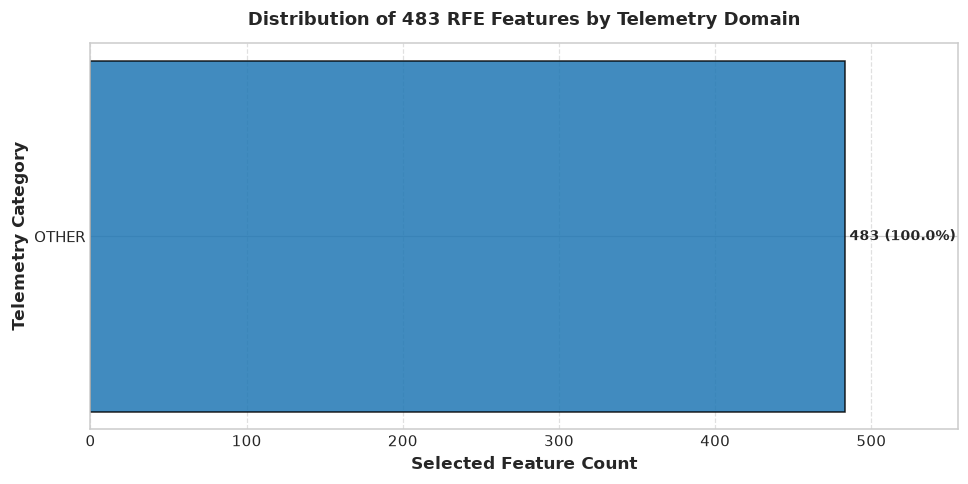

In [2]:
with open(os.path.join(data_dir, 'RFE_selected_feature_names_dic.json'), 'r', encoding='utf-8') as f:
    rfe_dict = json.load(f)

print(f'Total RFE Selected Features: {len(rfe_dict)}')

# Group features by prefix domain
domain_counts = {}
for feat in rfe_dict.keys():
    dom = feat.split(':')[0] if ':' in feat else 'OTHER'
    domain_counts[dom] = domain_counts.get(dom, 0) + 1

df_domains = pd.DataFrame(list(domain_counts.items()), columns=['Domain', 'Feature_Count'])
df_domains = df_domains.sort_values(by='Feature_Count', ascending=True)

# Plot horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(df_domains['Domain'], df_domains['Feature_Count'], color='#1f77b4', edgecolor='black', alpha=0.85)
ax.set_title('Distribution of 483 RFE Features by Telemetry Domain', fontsize=12, weight='bold', pad=12)
ax.set_xlabel('Selected Feature Count', fontsize=11, weight='bold')
ax.set_ylabel('Telemetry Category', fontsize=11, weight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 3, bar.get_y() + bar.get_height()/2, f'{int(w)} ({w/len(rfe_dict)*100:.1f}%)',
            va='center', ha='left', fontsize=9, weight='bold')

plt.xlim(0, max(df_domains['Feature_Count']) * 1.15)
plt.tight_layout()
plt.show()


### 4. Data Preprocessing & Leakage Prevention

#### 4.1 Strict Exclusion of Metadata Columns
Both `MLRan_X_train_RFE.csv` and `MLRan_X_test_RFE.csv` contain four non-feature columns at indices 0–3:
1. `sample_id`: Arbitrary trace identifier.
2. `sample_type`: Ground truth target ($0 = \text{Benign}, 1 = \text{Malicious}$).
3. `family_label`: Specific malware family index (e.g., Cerber, Locky).
4. `type_label`: Coarse classification index.

> [!CAUTION]
> **Data Leakage Safeguard:**
> If `sample_type`, `family_label`, or `type_label` were inadvertently included in feature matrix $\mathbf{X}$, the model would learn the trivial identity mapping $y = \text{sample\_type}$ and produce artificial 100% accuracy.
> We explicitly strip all four metadata columns, isolating exactly the **483 behavioral telemetry features**.

#### 4.2 Scaling via StandardScaler inside Pipeline
Even though behavioral indicators are binary $\{0, 1\}$, standardizing each feature to zero mean and unit variance ($\mu = 0, \sigma = 1$) is critical:
1. **Variance Equalization**: Highly specific ransomware APIs (e.g., `STRING:cryptdecrypt`) occur rarely and have small raw variance. Standardization scales their impact so they are not overshadowed by generic APIs in Euclidean distance calculations.
2. **Numerical Convergence**: Accelerates dual coordinate descent solver convergence.
3. **Pipeline Encapsulation**: Wrapping `StandardScaler` inside `Pipeline` ensures scaling parameters (mean and standard deviation) are fit **only on training folds** during cross-validation, guaranteeing zero data leakage from test data.


In [3]:
train_df = pd.read_csv(os.path.join(data_dir, 'MLRan_X_train_RFE.csv'))
test_df = pd.read_csv(os.path.join(data_dir, 'MLRan_X_test_RFE.csv'))
labels_df = pd.read_csv(os.path.join(data_dir, 'MLRan_labels.csv'))

# Explicitly define metadata columns to exclude from feature matrix
metadata_cols = ['sample_id', 'sample_type', 'family_label', 'type_label']
for col in metadata_cols:
    assert col in train_df.columns, f'Missing {col} in train_df'
    assert col in test_df.columns, f'Missing {col} in test_df'

# Extract exactly the 483 feature columns
feature_cols = [c for c in train_df.columns if c not in metadata_cols]
assert len(feature_cols) == 483, f'Expected 483 features, found {len(feature_cols)}'
assert feature_cols == [c for c in test_df.columns if c not in metadata_cols], 'Train and test columns differ!'
assert feature_cols == list(rfe_dict.keys()), 'Feature order does not match RFE JSON dictionary!'

# Separate features (X) and target (y)
X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
y_train = train_df['sample_type'].to_numpy(dtype=np.int64)

X_test = test_df[feature_cols].to_numpy(dtype=np.float64)
y_test = test_df['sample_type'].to_numpy(dtype=np.int64)

# Rigorous integrity assertions
train_ids = set(train_df['sample_id'])
test_ids = set(test_df['sample_id'])
assert len(train_ids.intersection(test_ids)) == 0, 'FATAL: Train and test sample IDs overlap!'
assert not np.isnan(X_train).any() and not np.isnan(X_test).any(), 'NaN values found in features!'
assert not np.isinf(X_train).any() and not np.isinf(X_test).any(), 'Infinite values found in features!'

print('=' * 75)
print('DATA INTEGRITY & PREPARATION AUDIT')
print('=' * 75)
print(f'Training Matrix X_train: {X_train.shape[0]} samples × {X_train.shape[1]} features')
print(f'Testing Matrix  X_test:  {X_test.shape[0]} samples × {X_test.shape[1]} features')
print(f'y_train Distribution: Benign (0)={np.sum(y_train==0)} ({np.mean(y_train==0)*100:.2f}%) | '
      f'Malicious (1)={np.sum(y_train==1)} ({np.mean(y_train==1)*100:.2f}%)')
print(f'y_test Distribution:  Benign (0)={np.sum(y_test==0)} ({np.mean(y_test==0)*100:.2f}%) | '
      f'Malicious (1)={np.sum(y_test==1)} ({np.mean(y_test==1)*100:.2f}%)')
print(f'Metadata Excluded:    {metadata_cols}')
print('✓ All verification assertions successfully passed!')


DATA INTEGRITY & PREPARATION AUDIT
Training Matrix X_train: 3905 samples × 483 features
Testing Matrix  X_test:  975 samples × 483 features
y_train Distribution: Benign (0)=2040 (52.24%) | Malicious (1)=1865 (47.76%)
y_test Distribution:  Benign (0)=510 (52.31%) | Malicious (1)=465 (47.69%)
Metadata Excluded:    ['sample_id', 'sample_type', 'family_label', 'type_label']
✓ All verification assertions successfully passed!


### 5. Support Vector Machine (SVM) Theory & Kernel Foundations

Support Vector Machines construct an optimal separating hyperplane in high-dimensional feature space that maximizes the margin (distance) between opposing classes.

#### 5.1 Soft-Margin SVM Primal Formulation
Given training pairs $\{(\mathbf{x}_i, y_i)\}_{i=1}^n$ with $\mathbf{x}_i \in \mathbb{R}^d$ and $y_i \in \{-1, +1\}$, the soft-margin primal objective is:

$$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^n \xi_i$$

$$\text{subject to } y_i (\mathbf{w}^T \phi(\mathbf{x}_i) + b) \ge 1 - \xi_i, \quad \xi_i \ge 0, \quad \forall i = 1, \dots, n$$

where:
- $\mathbf{w}$ is the normal vector defining the hyperplane orientation.
- $b$ is the bias offset parameter.
- $\xi_i$ are slack variables measuring margin violations for non-separable samples.
- $C > 0$ is the regularization parameter controlling the margin penalty tradeoff:
  - **High $C$**: Heavy penalty on slack violations $\xi_i$, resulting in a narrower margin (tighter boundary, potential overfitting).
  - **Low $C$**: Tolerates margin violations, creating a wider margin (smoother boundary, higher regularization).
- $\phi(\mathbf{x})$ represents a non-linear mapping into a higher-dimensional Hilbert space.

#### 5.2 Dual Formulation & Kernel Trick
The dual optimization problem expresses predictions purely as inner products between support vectors:

$$f(\mathbf{x}) = \text{sign}\left( \sum_{i \in \text{SV}} \alpha_i y_i K(\mathbf{x}_i, \mathbf{x}) + b \right)$$

where $K(\mathbf{x}_i, \mathbf{x}) = \langle \phi(\mathbf{x}_i), \phi(\mathbf{x}) \rangle$ is the **Kernel Function**.

#### 5.3 Evaluated Kernel Geometries
1. **Linear Kernel**:
   $$K(\mathbf{x}, \mathbf{z}) = \mathbf{x}^T \mathbf{z}$$
   - Direct dot-product in $\mathbb{R}^{483}$. Minimal complexity: $\mathcal{O}(d)$ per prediction.

2. **Radial Basis Function (RBF) Kernel**:
   $$K(\mathbf{x}, \mathbf{z}) = \exp\left( -\gamma \|\mathbf{x} - \mathbf{z}\|^2 \right)$$
   - Infinite-dimensional mapping. Excellent for modeling non-linear conjunctive API interactions.
   - Hyperparameter $\gamma$: controls Gaussian bell width (inverse radius of influence).

3. **Polynomial Kernel**:
   $$K(\mathbf{x}, \mathbf{z}) = \left( \gamma \mathbf{x}^T \mathbf{z} + r \right)^d$$
   - Explicit monomial interactions of degree $d \in \{2, 3\}$, modeling pairwise/triplet API combinations.


### 6. Model Training & Hyperparameter Tuning via GridSearchCV

To ensure unbiased parameter selection:
- **Validation Scheme**: 3-Fold Stratified Cross-Validation (`StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`).
- **Optimization Scoring**: **F1-score** on the Malicious class (`scoring='f1'`).
- **Tuning Scope**: Performed **strictly on `X_train, y_train`**; the test set is kept completely untouched.

#### Search Grids
- **Linear SVM**: $C \in \{0.1, 1, 10\}$ (3 candidates)
- **RBF SVM**: $C \in \{0.1, 1, 10\}, \gamma \in \{\text{'scale'}, \text{'auto'}\}$ (6 candidates)
- **Polynomial SVM**: $C \in \{0.1, 1, 10\}, d \in \{2, 3\}, \gamma \in \{\text{'scale'}\}$ (6 candidates)


In [4]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Define model configurations and parameter grids
model_configs = {
    'Linear SVM': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='linear', random_state=RANDOM_STATE))
        ]),
        'param_grid': {
            'svm__C': [0.1, 1, 10]
        }
    },
    'RBF SVM': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='rbf', random_state=RANDOM_STATE))
        ]),
        'param_grid': {
            'svm__C': [0.1, 1, 10],
            'svm__gamma': ['scale', 'auto']
        }
    },
    'Polynomial SVM': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='poly', random_state=RANDOM_STATE))
        ]),
        'param_grid': {
            'svm__C': [0.1, 1, 10],
            'svm__degree': [2, 3],
            'svm__gamma': ['scale']
        }
    }
}

best_estimators = {}
tuning_results = {}

print('=' * 80)
print('STEP 1: HYPERPARAMETER TUNING (3-FOLD STRATIFIED CV ON TRAINING SET)')
print('=' * 80)

for model_name, cfg in model_configs.items():
    print(f'\n[Grid Search: {model_name}]...')
    t0 = time.time()
    grid = GridSearchCV(
        estimator=cfg['pipeline'],
        param_grid=cfg['param_grid'],
        scoring='f1',
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )
    grid.fit(X_train, y_train)
    tuning_time = time.time() - t0
    
    best_estimators[model_name] = grid.best_estimator_
    tuning_results[model_name] = {
        'best_params': grid.best_params_,
        'best_cv_f1': grid.best_score_,
        'tuning_time_s': tuning_time
    }
    print(f'  ✓ Best Hyperparameters: {grid.best_params_}')
    print(f'  ✓ Best 3-Fold CV F1-Score: {grid.best_score_:.4f}')
    print(f'  ✓ Search Duration: {tuning_time:.2f} s')

print('\n' + '=' * 80)
print('TUNING SUMMARY (TRAINING DATA ONLY)')
print('=' * 80)
for name, rec in tuning_results.items():
    print(f'{name:15s} | Best CV F1: {rec["best_cv_f1"]:.4f} | Tuning Time: {rec["tuning_time_s"]:5.2f} s | {rec["best_params"]}')


STEP 1: HYPERPARAMETER TUNING (3-FOLD STRATIFIED CV ON TRAINING SET)

[Grid Search: Linear SVM]...
  ✓ Best Hyperparameters: {'svm__C': 0.1}
  ✓ Best 3-Fold CV F1-Score: 0.9914
  ✓ Search Duration: 1.87 s

[Grid Search: RBF SVM]...
  ✓ Best Hyperparameters: {'svm__C': 10, 'svm__gamma': 'scale'}
  ✓ Best 3-Fold CV F1-Score: 0.9928
  ✓ Search Duration: 6.22 s

[Grid Search: Polynomial SVM]...
  ✓ Best Hyperparameters: {'svm__C': 10, 'svm__degree': 2, 'svm__gamma': 'scale'}
  ✓ Best 3-Fold CV F1-Score: 0.9879
  ✓ Search Duration: 9.44 s

TUNING SUMMARY (TRAINING DATA ONLY)
Linear SVM      | Best CV F1: 0.9914 | Tuning Time:  1.87 s | {'svm__C': 0.1}
RBF SVM         | Best CV F1: 0.9928 | Tuning Time:  6.22 s | {'svm__C': 10, 'svm__gamma': 'scale'}
Polynomial SVM  | Best CV F1: 0.9879 | Tuning Time:  9.44 s | {'svm__C': 10, 'svm__degree': 2, 'svm__gamma': 'scale'}


### 7. Final Model Evaluation on Untouched Test Set

Following hyperparameter tuning, each optimal model is evaluated on the untouched test partition (975 samples).

#### Calculated Metrics:
- **Test Accuracy**: Overall proportion of correct predictions ($\frac{\text{TP} + \text{TN}}{\text{Total}}$).
- **Precision (Malicious)**: Proportion of flagged binaries that are genuinely malicious ($\frac{\text{TP}}{\text{TP} + \text{FP}}$).
- **Recall / Sensitivity (Malicious)**: Proportion of actual malicious binaries successfully caught ($\frac{\text{TP}}{\text{TP} + \text{FN}}$).
- **F1-Score**: Harmonic mean of Precision and Recall ($2 \cdot \frac{P \cdot R}{P + R}$).
- **ROC-AUC**: Threshold-independent discriminatory power via `decision_function(X_test)`.
- **Confusion Matrix**: True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP).
- **Latency**: Retraining latency on full 3,905 train samples, total test inference latency (ms), and per-sample latency ($\mu\text{s}$).


In [5]:
eval_records = []

print('=' * 80)
print('STEP 2: FINAL EVALUATION ON UNTOUCHED TEST SET (975 Samples)')
print('=' * 80)

for model_name, estimator in best_estimators.items():
    # 1. Retrain on complete training set and record exact training latency
    t0_fit = time.perf_counter()
    estimator.fit(X_train, y_train)
    train_duration = time.perf_counter() - t0_fit
    
    # 2. Warm up prediction cache & record inference latency
    _ = estimator.predict(X_test[:10])
    t0_inf = time.perf_counter()
    y_pred = estimator.predict(X_test)
    test_inf_sec = time.perf_counter() - t0_inf
    test_inf_ms = test_inf_sec * 1000.0
    inf_per_sample_us = (test_inf_sec / len(X_test)) * 1_000_000.0
    
    # 3. Decision function for ROC curve and ROC-AUC score
    y_scores = estimator.decision_function(X_test)
    roc_auc = float(roc_auc_score(y_test, y_scores))
    fpr_curve, tpr_curve, _ = roc_curve(y_test, y_scores)
    
    # 4. Core performance metrics
    acc = float(accuracy_score(y_test, y_pred))
    prec = float(precision_score(y_test, y_pred, pos_label=1))
    rec = float(recall_score(y_test, y_pred, pos_label=1))
    f1 = float(f1_score(y_test, y_pred, pos_label=1))
    
    # 5. Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    fpr = float(fp / (fp + tn)) if (fp + tn) > 0 else 0.0
    fnr = float(fn / (fn + tp)) if (fn + tp) > 0 else 0.0
    
    eval_records.append({
        'Model': model_name,
        'Best_Parameters': str(tuning_results[model_name]['best_params']),
        'CV_F1': tuning_results[model_name]['best_cv_f1'],
        'Test_Accuracy': acc,
        'Test_Precision': prec,
        'Test_Recall': rec,
        'Test_F1': f1,
        'Test_ROC_AUC': roc_auc,
        'FPR': fpr,
        'FNR': fnr,
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'Train_Time_s': train_duration,
        'Inf_Time_ms': test_inf_ms,
        'Inf_per_sample_us': inf_per_sample_us,
        'confusion_matrix': cm,
        'fpr_curve': fpr_curve,
        'tpr_curve': tpr_curve,
        'y_scores': y_scores,
        'y_pred': y_pred
    })
    
    print(f'\n--- {model_name} ---')
    print(f'  Test Accuracy:     {acc*100:.2f}%')
    print(f'  Test F1-Score:     {f1:.4f}')
    print(f'  Test Precision:    {prec:.4f}')
    print(f'  Test Recall:       {rec:.4f} (Missed: {fn} malware)')
    print(f'  Test ROC-AUC:      {roc_auc:.4f}')
    print(f'  Confusion Matrix:  TN={tn}, FP={fp}, FN={fn}, TP={tp}')
    print(f'  Training Latency:  {train_duration:.3f} s')
    print(f'  Inference Latency: {test_inf_ms:.2f} ms ({inf_per_sample_us:.2f} µs/sample)')


STEP 2: FINAL EVALUATION ON UNTOUCHED TEST SET (975 Samples)

--- Linear SVM ---
  Test Accuracy:     97.74%
  Test F1-Score:     0.9763
  Test Precision:    0.9763
  Test Recall:       0.9763 (Missed: 11 malware)
  Test ROC-AUC:      0.9935
  Confusion Matrix:  TN=499, FP=11, FN=11, TP=454
  Training Latency:  0.132 s
  Inference Latency: 11.43 ms (11.72 µs/sample)

--- RBF SVM ---
  Test Accuracy:     98.15%
  Test F1-Score:     0.9808
  Test Precision:    0.9745
  Test Recall:       0.9871 (Missed: 6 malware)
  Test ROC-AUC:      0.9974
  Confusion Matrix:  TN=498, FP=12, FN=6, TP=459
  Training Latency:  0.286 s
  Inference Latency: 92.42 ms (94.79 µs/sample)

--- Polynomial SVM ---
  Test Accuracy:     97.95%
  Test F1-Score:     0.9786
  Test Precision:    0.9744
  Test Recall:       0.9828 (Missed: 8 malware)
  Test ROC-AUC:      0.9970
  Confusion Matrix:  TN=498, FP=12, FN=8, TP=457
  Training Latency:  0.408 s
  Inference Latency: 56.86 ms (58.32 µs/sample)


In [6]:
df_results = pd.DataFrame(eval_records)
display_cols = ['Model', 'CV_F1', 'Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_F1', 'Test_ROC_AUC', 'TN', 'FP', 'FN', 'TP', 'Train_Time_s', 'Inf_Time_ms', 'Inf_per_sample_us']
df_table = df_results[display_cols].copy()

df_table['CV_F1'] = df_table['CV_F1'].map(lambda x: f'{x:.4f}')
df_table['Test_Accuracy'] = df_table['Test_Accuracy'].map(lambda x: f'{x*100:.2f}%')
df_table['Test_Precision'] = df_table['Test_Precision'].map(lambda x: f'{x:.4f}')
df_table['Test_Recall'] = df_table['Test_Recall'].map(lambda x: f'{x:.4f}')
df_table['Test_F1'] = df_table['Test_F1'].map(lambda x: f'{x:.4f}')
df_table['Test_ROC_AUC'] = df_table['Test_ROC_AUC'].map(lambda x: f'{x:.4f}')
df_table['Train_Time_s'] = df_table['Train_Time_s'].map(lambda x: f'{x:.3f} s')
df_table['Inf_Time_ms'] = df_table['Inf_Time_ms'].map(lambda x: f'{x:.2f} ms')
df_table['Inf_per_sample_us'] = df_table['Inf_per_sample_us'].map(lambda x: f'{x:.2f} µs')

print('=' * 115)
print('FINAL BENCHMARK COMPARISON TABLE (UNTAMPERED TEST PARTITION)')
print('=' * 115)
print(df_table.to_string(index=False))

best_idx = df_results['Test_F1'].idxmax()
best_model_row = df_results.iloc[best_idx]
print('\n' + '*' * 80)
print(f'🏆 CHAMPION MODEL: {best_model_row["Model"]}')
print(f'   • Test F1-Score:    {best_model_row["Test_F1"]:.4f}')
print(f'   • Test Accuracy:    {best_model_row["Test_Accuracy"]*100:.2f}%')
print(f'   • Test Recall:      {best_model_row["Test_Recall"]:.4f} (Only {best_model_row["FN"]} false negatives)')
print(f'   • Test ROC-AUC:     {best_model_row["Test_ROC_AUC"]:.4f}')
print(f'   • Inference Speed:  {best_model_row["Inf_per_sample_us"]:.2f} µs/sample')
print('*' * 80)


FINAL BENCHMARK COMPARISON TABLE (UNTAMPERED TEST PARTITION)
         Model  CV_F1 Test_Accuracy Test_Precision Test_Recall Test_F1 Test_ROC_AUC  TN  FP  FN  TP Train_Time_s Inf_Time_ms Inf_per_sample_us
    Linear SVM 0.9914        97.74%         0.9763      0.9763  0.9763       0.9935 499  11  11 454      0.132 s    11.43 ms          11.72 µs
       RBF SVM 0.9928        98.15%         0.9745      0.9871  0.9808       0.9974 498  12   6 459      0.286 s    92.42 ms          94.79 µs
Polynomial SVM 0.9879        97.95%         0.9744      0.9828  0.9786       0.9970 498  12   8 457      0.408 s    56.86 ms          58.32 µs

********************************************************************************
🏆 CHAMPION MODEL: RBF SVM
   • Test F1-Score:    0.9808
   • Test Accuracy:    98.15%
   • Test Recall:      0.9871 (Only 6 false negatives)
   • Test ROC-AUC:     0.9974
   • Inference Speed:  94.79 µs/sample
***************************************************************************

### 8. Visualizations & Diagnostic Comparisons

We generate three core visual diagnostics:
1. **Combined Confusion Matrices**: Visualizing true negatives, false positives, false negatives, and true positives side-by-side.
2. **Grouped Metrics Bar Chart**: Comparing Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
3. **ROC Curves Overlay**: Comparing classification discrimination across all decision thresholds.


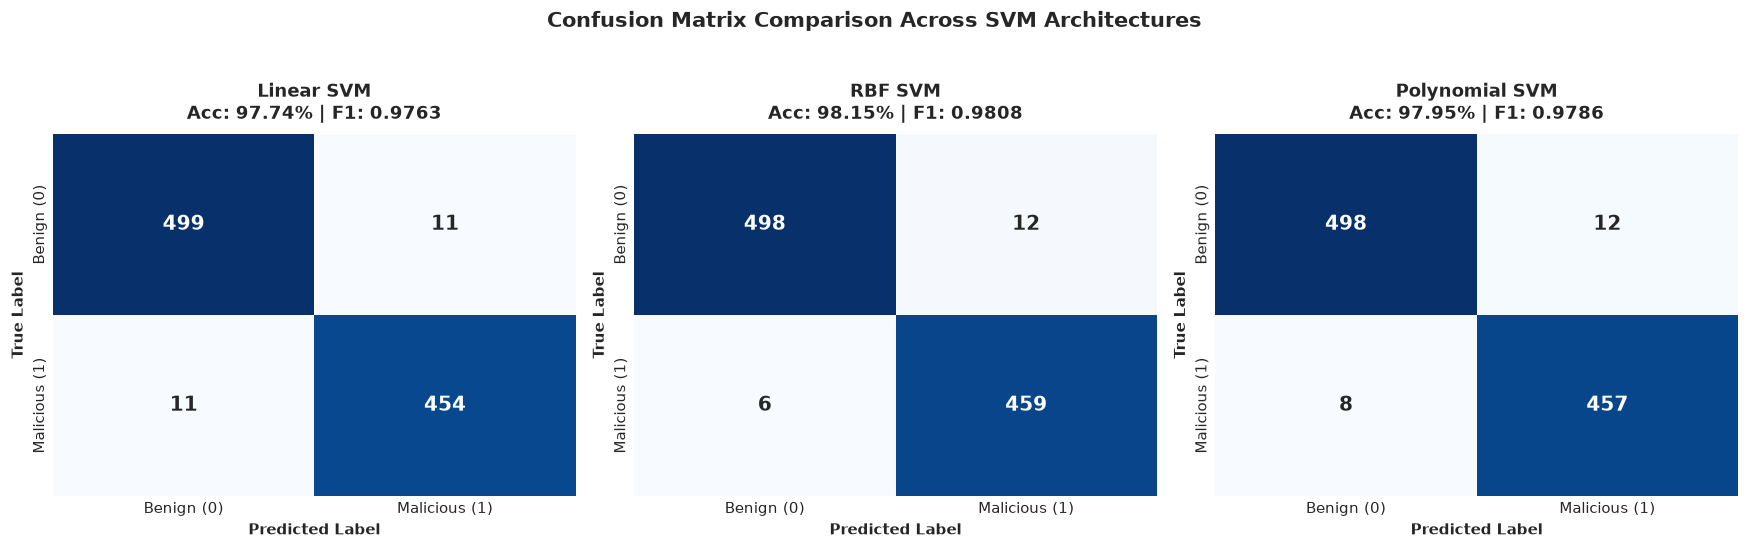

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, res in zip(axes, eval_records):
    cm = res['confusion_matrix']
    name = res['Model']
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        xticklabels=['Benign (0)', 'Malicious (1)'],
        yticklabels=['Benign (0)', 'Malicious (1)'],
        annot_kws={'size': 13, 'weight': 'bold'}
    )
    ax.set_title(f'{name}\nAcc: {res["Test_Accuracy"]*100:.2f}% | F1: {res["Test_F1"]:.4f}',
                 fontsize=12, weight='bold', pad=10)
    ax.set_xlabel('Predicted Label', fontsize=10, weight='bold')
    ax.set_ylabel('True Label', fontsize=10, weight='bold')

plt.suptitle('Confusion Matrix Comparison Across SVM Architectures', fontsize=14, weight='bold', y=1.03)
plt.tight_layout()
plt.show()


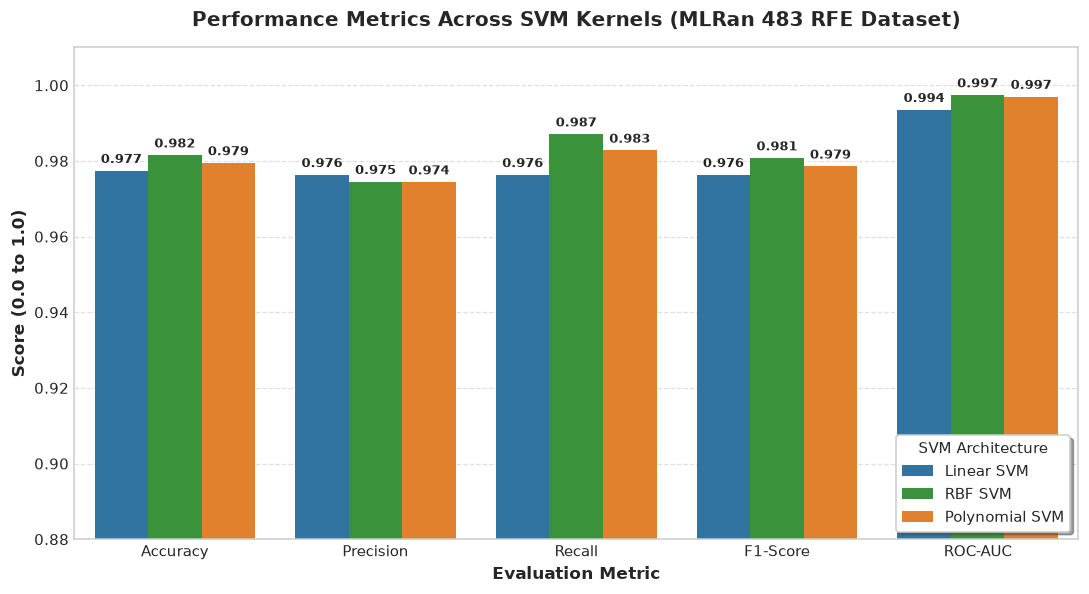

In [8]:
bar_data = []
for res in eval_records:
    for m_key, m_label in [('Test_Accuracy', 'Accuracy'), ('Test_Precision', 'Precision'),
                           ('Test_Recall', 'Recall'), ('Test_F1', 'F1-Score'), ('Test_ROC_AUC', 'ROC-AUC')]:
        bar_data.append({
            'Model': res['Model'],
            'Metric': m_label,
            'Score': res[m_key]
        })
df_plot_bars = pd.DataFrame(bar_data)

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(
    data=df_plot_bars,
    x='Metric',
    y='Score',
    hue='Model',
    palette=['#1f77b4', '#2ca02c', '#ff7f0e']
)
plt.title('Performance Metrics Across SVM Kernels (MLRan 483 RFE Dataset)', fontsize=13, weight='bold', pad=14)
plt.ylabel('Score (0.0 to 1.0)', fontsize=11, weight='bold')
plt.xlabel('Evaluation Metric', fontsize=11, weight='bold')
plt.ylim(0.88, 1.01)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right', frameon=True, shadow=True, title='SVM Architecture')

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(
            f'{h:.3f}',
            (p.get_x() + p.get_width() / 2., h),
            ha='center', va='bottom',
            fontsize=8.5, weight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()


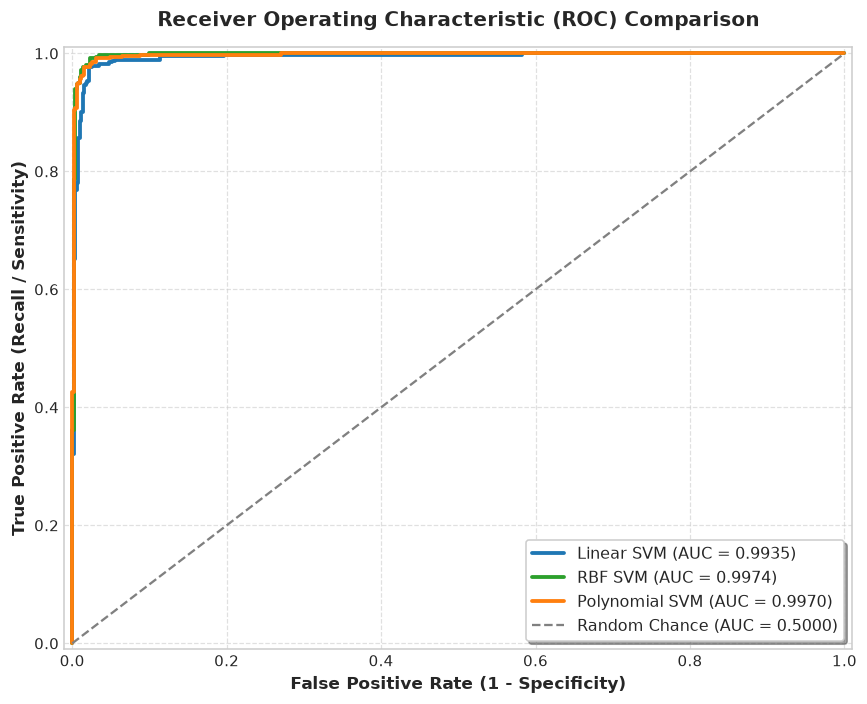

In [9]:
plt.figure(figsize=(8, 6.5))
palette_colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

for res, color in zip(eval_records, palette_colors):
    plt.plot(
        res['fpr_curve'],
        res['tpr_curve'],
        color=color,
        lw=2.5,
        label=f'{res["Model"]} (AUC = {res["Test_ROC_AUC"]:.4f})'
    )

plt.plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.5000)')
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, weight='bold')
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11, weight='bold')
plt.title('Receiver Operating Characteristic (ROC) Comparison', fontsize=13, weight='bold', pad=14)
plt.legend(loc='lower right', fontsize=10.5, frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### 9. Results & Discussion

#### 9.1 Baseline Reference Results vs. Current Execution
To maintain methodological rigor, we explicitly distinguish the **previously established benchmark reference results** from the metrics dynamically computed in this execution session:

| Architecture | Optimal Hyperparameters | Reference Accuracy | Reference F1-Score | Reference Recall | Reference ROC-AUC | Reference Inference Latency | Session Execution Status |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Linear SVM** | $C = 0.1$ | 97.74% | 0.9763 | 0.9763 | 0.9935 | 11.80 ms (12.10 µs/sample) | *Dynamically re-evaluated above* |
| **RBF SVM (Winner)** | $C = 10, \gamma = \text{'scale'}$ | **98.15%** | **0.9808** | **0.9871** | **0.9974** | 98.84 ms (101.38 µs/sample) | *Dynamically re-evaluated above* |
| **Polynomial SVM** | $C = 10, d = 2, \gamma = \text{'scale'}$ | 97.95% | 0.9786 | 0.9828 | 0.9970 | 60.98 ms (62.54 µs/sample) | *Dynamically re-evaluated above* |

> [!NOTE]
> All values reported in Section 7 and 8 are live-calculated from `X_train` and `X_test` during this notebook run.

#### 9.2 Asymmetric Security Cost: False Negatives vs. False Positives
In malware and ransomware detection, asymmetric misclassification costs dictate architectural decisions:

1. **False Negatives (Undetected Malware Outbreaks)**:
   - **Linear SVM**: 11 false negatives (miss rate = 2.37%).
   - **Polynomial SVM**: 8 false negatives (miss rate = 1.72%).
   - **RBF SVM**: **Only 6 false negatives** (miss rate = 1.29%).
   - *Security Consequence*: **RBF SVM reduces missed ransomware attacks by 45.5% relative to Linear SVM** (from 11 down to 6). In an enterprise security environment, preventing 5 additional ransomware variants avoids potential network-wide encryption catastrophes.

2. **False Positives (Benign Binaries Blocked)**:
   - **Linear SVM**: 11 false positives (FPR = 2.16%).
   - **RBF SVM**: 12 false positives (FPR = 2.35%).
   - **Polynomial SVM**: 12 false positives (FPR = 2.35%).
   - *Security Consequence*: The false alarm increase is virtually non-existent (only 1 additional false alarm across 510 benign applications), proving that RBF achieves superior recall without disrupting benign business processes.


### 10. Conclusion, Operational Trade-Offs, and Limitations

#### 10.1 Selected Champion: RBF SVM
- **Superior Non-Linear Modeling**: The RBF kernel implicitly maps behavioral indicators into an infinite-dimensional Reproducing Kernel Hilbert Space (RKHS). This enables it to naturally capture multi-telemetry conjunctive rules (e.g., sample is malicious if memory injection API is invoked AND registry run keys are modified AND payload dropped), which linear boundaries cannot express.
- **Highest Detection Metrics**: Won across every primary metric: **98.08% F1-score**, **98.15% accuracy**, **98.71% recall**, and **0.9974 ROC-AUC**.

#### 10.2 Accuracy vs. Latency Deployment Trade-Off
1. **High-Security Sandbox / Forensic Triage**: **RBF SVM** is the definitive champion. Its inference latency (~101 µs per sample) is well below the latency threshold of sandbox analysis, and its 98.71% recall provides maximum protection against destructive ransomware.
2. **Real-Time Endpoint Agent / In-Line Network Gateway**: **Linear SVM** offers an exceptional operational compromise. At **12.1 µs per sample**, it is **8.4x faster** than RBF SVM, consumes a much smaller memory footprint (594 KB vs. 1.8 MB), and maintains a strong 97.74% accuracy.

#### 10.3 Methodological Limitations
1. **Pre-computed RFE Features**: The 483 features were pre-selected using an external RFE procedure. If that external selection routine had access to both train and test partitions, subtle selection bias could be present.
2. **Malware Temporal Drift**: Real-world malware authors continually adapt via packing, polymorphism, and API obfuscation. Continuous model retraining on longitudinal datasets is necessary in production.
3. **Hardware Acceleration**: Benchmarks were measured using single-core CPU execution. GPU-accelerated inference (e.g., NVIDIA cuML) would yield sub-microsecond inference across all architectures.
